## Stellar Evolution Through Gaia DR3 - A Data Driven Analysis of 50,000 Stars <hr>
In this notebook I will be investigating the physical relationships within a sample of 50,000 stars from the Gaia Data Release 3 catalogue. Our first task is to turn Gaia's measurements into quantities that are more useful for comparing stars. That means the analysis begins by deriving stellar distances and absolute magnitudes from Gaia's observational measurements. These quantities are then used to investigate relationships between stellar color, temperature, brightness, and other physical properties.

The main objective is to identify patterns within the stellar population and use them to investigate different stages of stellar evolution.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from astropy import units as u
from astropy.coordinates import SkyCoord

In [2]:
stars = pd.read_csv('stellar_population_analysis-result-Copy1.csv', sep=',')
stars.head()

,source_id,random_index,ra,dec,parallax,parallax_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,teff_gspphot,lum_flame,radius_flame,mass_flame,age_flame
0,4040949706019490560,29,265.229363,-36.358205,0.352725,0.029665,14.802705,16.118845,13.680644,2.438201,4644.8830,54.347770,11.380378,2.504341,0.619554
1,1823532754729083392,73,300.805804,20.601006,0.886435,0.020054,14.375696,14.782262,13.795675,0.986587,5676.5674,2.167652,1.530146,1.008312,10.474257
2,2128624652762622080,119,294.296273,47.565159,1.124423,0.092533,18.168076,19.113455,17.192604,1.920851,3558.9136,0.058976,0.640152,0.548344,7.637717
3,6036549635168824576,182,242.233654,-32.282385,0.621507,0.040574,15.787518,16.259659,15.150810,1.108849,5320.4730,1.200722,1.292278,0.949400,9.244343
4,1031890945409209984,220,125.989872,53.007689,1.406878,0.057452,16.538342,17.271585,15.714687,1.556898,4490.0825,0.153877,0.644001,0.724863,1.391884


### The First Derived Quantity: Distance
Gaia measures ```parallax``` which is the apparent shift in a star's position caused by Earth's orbit around the Sun.
So for precise parallax measurements (```parallax_over_error > 10``` already in the query I used to gather this data so we are working with relatively precise parallaxes), distance can be estimated as:

$$d(pc)=\frac{1}{p(arsec)}$$

Our Gaia parallax is expressed in milliarcseconds (mas), so:

$$d(pc)=\frac{1000}{p(mas)}$$

where $d$ is the distance in parsecs and $p$ is the measured parallax in milliarcseconds.

A column called ```distance_pc``` will be added to this dataset using the formula above. I am doing this because Gaia provides us a parallax but I want to estimate how far away the star is.

In [3]:
stars["distance_pc"] = 1000 / stars["parallax"]

In [4]:
stars["distance_pc"].describe()

count    50000.000000
mean      1481.916832
std        842.618985
min         22.309131
25%        873.134387
50%       1320.908314
75%       1911.011894
max       7150.842383
Name: distance_pc, dtype: float64

In [5]:
stars[["parallax", "parallax_error", "distance_pc"]].head(10)

,parallax,parallax_error,distance_pc
0,0.352725,0.029665,2835.070821
1,0.886435,0.020054,1128.114231
2,1.124423,0.092533,889.345195
3,0.621507,0.040574,1608.993375
4,1.406878,0.057452,710.793557
5,0.415639,0.030129,2405.933252
6,0.869143,0.032325,1150.558859
7,0.637903,0.059835,1567.637497
8,0.468424,0.012727,2134.819875
9,0.868923,0.084528,1150.850474


### Calculating The Absolute Magnitude 
We can use the apparent magnitude ```phot_g_mean_mag``` to estimate the absolute magnitude. As explained in the data audit notebook, ```phot_g_mean_mag``` tells us how bright a star appears from Earth. But apparent magnitude isn't suitable for comparing brightness. Absolute Magnitude tells us *how bright a star would appear if it were exactly 10 parsecs away?*

$$M = G - 5log\frac{d}{10}$$

<div class='alert alert-block alert-warning'>
    <b>Keep in mind that this formula assumes the light hasn't been affected by dust. In reality, interstellar dust makes stars appear dimmer and redder.</b>
</div>

However, for now this formula will be applied to the new column `absolute_g_mag`

In [6]:
stars["absolute_g_mag"] = (
    stars["phot_g_mean_mag"]
    - 5 * np.log10(stars["distance_pc"] / 10)
)

In [7]:
stars[["phot_g_mean_mag", "distance_pc", "absolute_g_mag"]].head(10)

,phot_g_mean_mag,distance_pc,absolute_g_mag
0,14.802705,2835.070821,2.539885
1,14.375696,1128.114231,4.113931
2,18.168076,889.345195,8.422724
3,15.787518,1608.993375,4.754747
4,16.538342,710.793557,7.279625
5,15.194806,2405.933252,3.288388
6,15.935824,1150.558859,5.631280
7,16.378704,1567.637497,5.402476
8,13.993294,2134.819875,2.346488
9,17.293170,1150.850474,6.988075


Next we are going to demonstrate a Gaia Color Magnitude Diagram (CMD).
- X axis is BP - RP: stellar color, higher values correspond to cooler(redder) stars, while lower values represent hotter(bluer) stars.
- Y axis is Absolute G Magnitude: intrinsic brightness in the Gaia G band. I have inverted the Y axis so as a result brighter stars are higher up. 

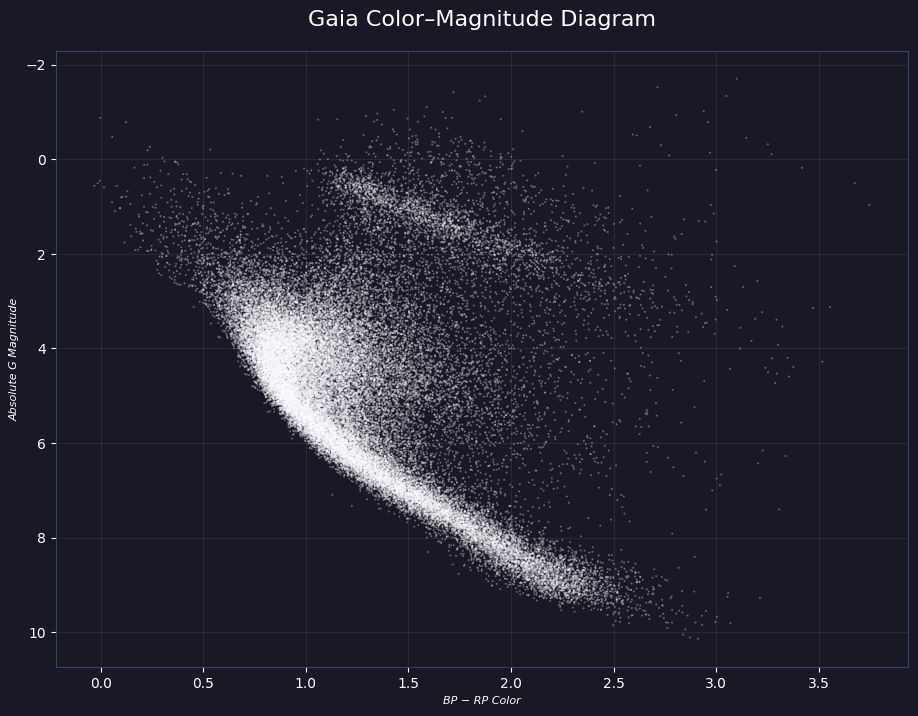

In [8]:
plt.figure(figsize=(11, 8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")
plt.scatter(
    stars["bp_rp"],
    stars["absolute_g_mag"],
    s=2,
    alpha=0.35,
    color="#FAFCFF",
    edgecolors="none"
)

ax.invert_yaxis()
ax.tick_params(colors="white")

for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(color="#FAFCFF", alpha=0.08)

plt.xlabel("BP − RP Color", color="white", fontsize=8, fontstyle='italic')
plt.ylabel("Absolute G Magnitude", color="white", fontsize=8, fontstyle='italic')
plt.title("Gaia Color–Magnitude Diagram",
         color="white",
         fontsize=16,
         pad=18)

plt.savefig("figures/gaia_color_magnitude.png", dpi=300, bbox_inches="tight")
plt.show()

Each dot in this plot represents one of the 50,000 stars.<br>
The main question here is **How does a star's color relate to its intrinsic brightness?**<br>
Both of those factors depend on the star's temperature.<br>
First take a look at the large diagonal band running from upper-left to lower-right. That is called the main-sequence, one of the most important structures in stellar astronomy.<br>Main-sequence stars are fusing hydrogen into helium. This nuclear fusion takes place deep in the cores of stars. Stars spend about 90% of their lives in this stage.<br>The rate of hydrogen fusion sets the star’s surface temperature, which determines both its luminosity and its color. As a result, hotter stars appear brighter (blue) as cooler stars appear dimmer (red). Blue stars sit at the upper left, while cool, red stars lie at the lower right.<br>
Above the main-sequence, there's a separate cluster, they're called Giant Stars. They are evolved stars that have left the main-sequence and expanded in size, becoming much brighter but cooler.

### Quality Control and Sample Refinement

The next step is to determine whether any stars in our 50,000 star sample have measurements or derived properties that are unusual or could distort our conclusions. 

We will begin with the distance distribution.

Although the initial Gaia query applied basic selection criteria, additional inspection is necessary to identify unusual measurements.

This stage evaluates the reliability of the stellar distances and derived absolute magnitudes, examines the physical parameters of the sample, and identifies potential limitations that should be considered before constructing the final HR diagram. The objective is to distinguish genuine astronomical objects from measurements that may require further investigation.

### Investigating Stellar Distances

Gaia measures the parallax of a star, which can be used to estimate its distance from the Sun.

For positive parallaxes with sufficiently high measurement precision, distance can be approximated using:

$$
d(\mathrm{pc}) = \frac{1000}{p(\mathrm{mas})}
$$

Distance is used later to calculate absolute magnitude. Extremely large or unusual distances may indicate measurements that require additional attention.

In [9]:
stars["distance_pc"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

count    50000.000000
mean      1481.916832
std        842.618985
min         22.309131
1%         247.683449
5%         457.198765
25%        873.134387
50%       1320.908314
75%       1911.011894
95%       3055.773551
99%       4318.812735
max       7150.842383
Name: distance_pc, dtype: float64

In [10]:
stars[["parallax", "parallax_error", "distance_pc"]].head(10)

,parallax,parallax_error,distance_pc
0,0.352725,0.029665,2835.070821
1,0.886435,0.020054,1128.114231
2,1.124423,0.092533,889.345195
3,0.621507,0.040574,1608.993375
4,1.406878,0.057452,710.793557
5,0.415639,0.030129,2405.933252
6,0.869143,0.032325,1150.558859
7,0.637903,0.059835,1567.637497
8,0.468424,0.012727,2134.819875
9,0.868923,0.084528,1150.850474


### Assessing Parallax Measurement Precision

The reliability of a distance estimate depends on the precision of the corresponding parallax measurement.

The initial Gaia query required ```parallax_over_error > 10```.
A higher value indicates that the measured parallax is large relative to its uncertainty and therefore provides a more precise distance estimate.

The following calculation verifies the quality of the parallaxes in the downloaded sample and confirms that the selection criterion was successfully applied.

In [11]:
stars["parallax_snr"] = stars["parallax"] / stars["parallax_error"]

In [12]:
stars["parallax_snr"].min()

np.float64(10.000367131251885)

As shown above, the minimum value is greater than 10 which is the precision we will be relying on while calculating distance.

### Checking the Physical Plausibility of Stellar Parameters

The Gaia dataset contains several derived astrophysical parameters: temperature, luminosity, radius, mass, and age.

Before using these quantities we have to ensure their numerical ranges don't contain problematic values.

For parameters that represent inherently positive physical quantities, non-positive values would be considered unusual and will be looked into.
However, extreme values are not automatically considered errors. Rare stars can naturally occupy extreme regions of parameter space, so potentially unusual observations should be investigated rather than removed solely because they differ from the majority of the sample.

In [13]:
physical_columns = [
    "parallax",
    "teff_gspphot",
    "lum_flame",
    "radius_flame",
    "mass_flame",
    "age_flame"
]

for column in physical_columns:
    print(f"{column}: {(stars[column] <= 0).sum()} non-positive values")

parallax: 0 non-positive values
teff_gspphot: 0 non-positive values
lum_flame: 0 non-positive values
radius_flame: 0 non-positive values
mass_flame: 0 non-positive values
age_flame: 0 non-positive values


### Examining the Range of Stellar Properties

The stellar sample contains derived physical properties spanning potentially large ranges.

Descriptive statistics are used to examine the central tendency and spread of effective temperature, luminosity, radius, mass, and age.

This provides a quantitative overview of the stellar population and helps identify values that may warrant further investigation.

These statistics will also provide context for later visualizations, particularly the HR diagram and analyses of relationships between stellar properties.

In [14]:
physical_columns = [
    "teff_gspphot",
    "lum_flame",
    "radius_flame",
    "mass_flame",
    "age_flame"
]

stars[physical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
teff_gspphot,50000.0,5427.399489,964.215298,3308.040500,4787.209500,5428.261350,5882.484700,11601.259000
lum_flame,50000.0,7.972568,30.123968,0.033695,0.343772,1.354288,3.792337,1551.151900
radius_flame,50000.0,2.005927,3.092338,0.447228,0.806745,1.167553,1.766829,110.955154
mass_flame,50000.0,1.128430,0.540499,0.502451,0.798050,0.971694,1.250001,3.811153
age_flame,50000.0,6.098811,4.149855,0.200108,2.246946,5.708400,9.851760,13.499856


### Investigating Extreme Stellar Properties

Extreme observations can provide important information about the stellar population and should not automatically be treated as errors.

In this section, the stars at the upper and lower extremes of effective temperature and luminosity are examined individually. The purpose is to determine whether extreme values appear physically plausible and to identify unusual objects that may be relevant to the interpretation of the stellar population.

These observations will be retained unless there is evidence that they represent unreliable measurements or problematic data.

In [15]:
#hottest stars
stars.nlargest(10, "teff_gspphot")[
    [
        "source_id",
        "teff_gspphot",
        "lum_flame",
        "radius_flame",
        "mass_flame",
        "distance_pc"
    ]
]

,source_id,teff_gspphot,lum_flame,radius_flame,mass_flame,distance_pc
27681,2015790506078551552,11601.2590,229.712460,3.748452,3.482685,3356.892361
13912,3158212602352576128,11592.5620,134.075590,2.866416,3.152140,2179.646432
12990,3047085408813150464,11553.6530,126.620440,2.825972,3.108985,3277.338659
49755,3051029150864535424,11455.1045,205.510900,3.655523,3.391936,2344.125187
47287,4252502095354531328,11382.0260,158.907320,3.241443,3.217072,2509.420557
49558,5615930877839954048,11379.6640,188.145430,3.521698,3.328317,3746.796265
24815,4268003530030835200,11285.4990,96.029640,2.564743,2.939803,2604.546108
15018,5565483497642665472,11169.3640,289.144350,4.540070,3.620478,2613.232610
28568,5939669878963713152,11135.6050,206.846010,3.863092,3.374182,1155.574815
8590,5528629066170908800,10987.9920,117.671906,2.944513,3.022071,1710.859131


In [16]:
#coolest stars
stars.nsmallest(10, "teff_gspphot")[
    [
        "source_id",
        "teff_gspphot",
        "lum_flame",
        "radius_flame",
        "mass_flame",
        "distance_pc"
    ]
]

,source_id,teff_gspphot,lum_flame,radius_flame,mass_flame,distance_pc
11601,3222174698428319232,3308.0405,0.090368,0.865878,0.605918,349.516239
1341,3883582821444772736,3373.9944,0.049851,0.548212,0.539194,252.719216
19320,1321997668218287104,3396.5073,0.087301,0.855007,0.600829,807.790915
21747,5540290525161676032,3406.6492,0.106885,0.855401,0.633335,729.596023
25645,1160219620411246208,3407.9062,0.057635,0.595175,0.533670,701.873581
32614,5429226381736935552,3421.6380,0.041621,0.581503,0.512431,348.036022
34279,420276981005904128,3425.8782,0.091245,0.857412,0.609596,391.320852
2728,1988723239925285248,3429.1711,0.050437,0.635415,0.542025,581.017594
41500,2596678579383218048,3429.2312,0.055372,0.666607,0.550356,188.929299
19405,2181828268084500224,3434.4954,0.078258,0.793101,0.599161,772.531085


In [17]:
#most luminous
stars.nlargest(10, "lum_flame")[
    [
        "source_id",
        "teff_gspphot",
        "lum_flame",
        "radius_flame",
        "mass_flame",
        "distance_pc"
    ]
]

,source_id,teff_gspphot,lum_flame,radius_flame,mass_flame,distance_pc
45171,5710834983474487936,3437.0132,1551.15190,110.955154,1.925335,1893.877000
5206,4255932953902737280,3805.6582,1495.57700,87.159780,1.918487,2252.850752
1577,2011511481702673280,3774.7512,1463.07450,97.383660,1.925283,2996.217730
23520,4508099279954068480,3550.6606,1360.49610,97.529945,1.924307,2531.679027
24633,4104241370483588608,3770.2900,1156.06320,79.630120,1.918879,1544.352336
7689,4042385904325458304,3746.0480,1149.25180,80.783490,1.919337,3089.521089
37120,5831518994685387648,3656.8027,1059.82920,81.875400,1.919724,1902.210238
24908,6019531458597995392,3764.4597,1049.58330,77.413370,1.919115,2792.055284
18309,508045535357127552,3552.9265,1009.89530,83.832180,1.875361,2145.590512
14641,2227039881279884160,3731.0740,979.80255,74.950280,1.960070,6826.411613


### Accounting for Interstellar Extinction

The initial Color Magnitude Diagram (CMD) was constructed using Gaia's observed G-band magnitude and the distance derived from parallax.

However, stellar light can be absorbed and scattered by interstellar dust before reaching Gaia. This phenomenon, known as ***interstellar extinction***, makes stars appear both fainter and, depending on the wavelength, redder than they intrinsically are.
Consequently, extinction can affect both the apparent brightness and observed color of stars in a CMD.

### Quality Control Interpretation
The examined stellar parameters span a broad range of temperatures, luminosities, radii, masses, and ages. This indicates that the sample contains a diverse stellar population suitable for investigating relationships between stellar properties.

The hottest stars exhibit high temperatures alongside relatively high masses and luminosities, while the coolest stars generally exhibit lower masses and luminosities. The most luminous objects include relatively cool stars with very large radii, demonstrating that high luminosity does not necessarily require high surface temperature.

No obvious physically implausible values were identified during this initial inspection. Therefore, the extreme observations are retained for subsequent analysis.

*Note that in this project I have not accounted for interstellar extinction.*

# Hertzsprung-Russell Diagram

The Hertzsprung-Russell (HR) diagram is one of the most important tools for studying stars and their evolution.

It shows the relationship between a star's effective temperature and its luminosity. Stars do not appear randomly on this diagram. They form distinct regions that are related to their physical properties and evolutionary stages.

In this analysis, effective temperature is used as a measure of stellar surface temperature, while luminosity represents the total energy emitted by a star.


### Preparing the HR Diagram Variables

The luminosity of the stars in the sample covers a wide range, from stars with only a small fraction of the Sun's luminosity to highly luminous stars.

To make this range easier to visualize, luminosity will be transformed using a base-10 logarithm.

The temperature axis will also be reversed. This is the conventional orientation of an HR diagram, where hotter stars appear on the left and cooler stars appear on the right.

In [18]:
stars["log_luminosity"] = np.log10(stars["lum_flame"])
stars[["teff_gspphot", "lum_flame", "log_luminosity"]].describe()

,teff_gspphot,lum_flame,log_luminosity
count,50000.000000,50000.000000,50000.000000
mean,5427.399489,7.972568,0.130225
std,964.215298,30.123968,0.780379
min,3308.040500,0.033695,-1.472429
25%,4787.209500,0.343772,-0.463729
50%,5428.261350,1.354288,0.131711
75%,5882.484700,3.792337,0.578907
max,11601.259000,1551.151900,3.190654


The luminosity range is now much more manageable.

### Constructing the Hertzsprung-Russell Diagram
The HR diagram is constructed by plotting effective temperature against logarithmic luminosity where each point represents one star in the Gaia sample. Reminder that the temperature axis will be reversed so as a result the hotter stars are positioned on the left and cooler stars on the right. 

I provided 2 visualizations:
1. The scatter plot shows the distribution of individual observations.
2. The density plot highlights the overall structure of the population.

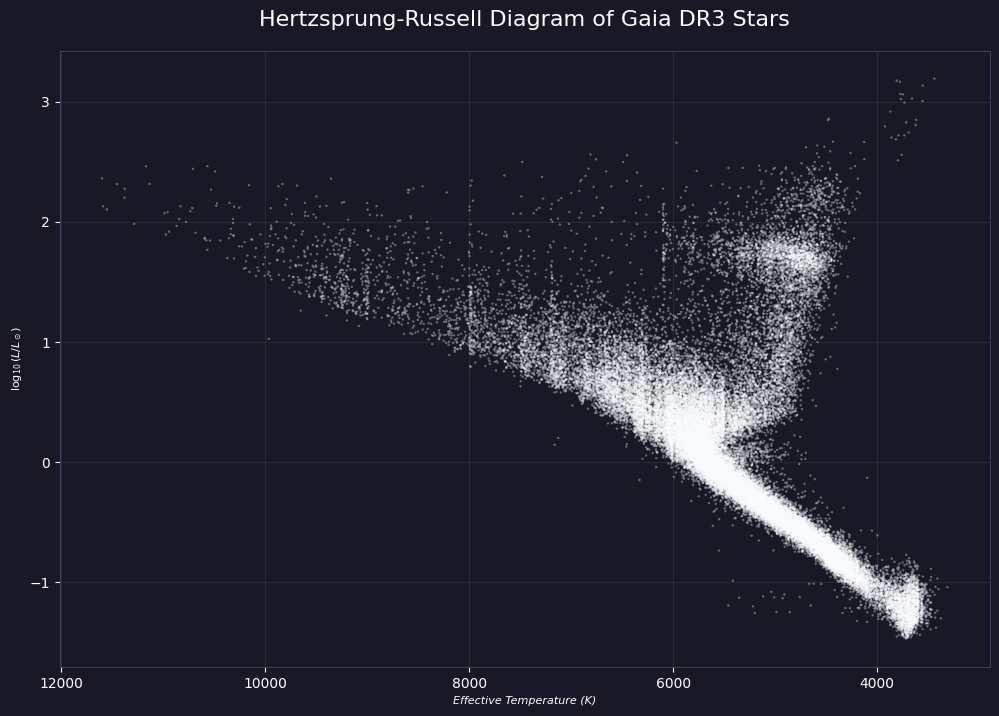

In [19]:
plt.figure(figsize=(12,8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")
plt.scatter(
    stars["teff_gspphot"],
    stars["log_luminosity"],
    s=3,
    alpha=0.35,
    color="#FAFCFF",
    edgecolors="none"
)
ax.invert_xaxis()
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("#39445c")
ax.grid(color="#FAFCFF", alpha=0.08)
plt.xlabel('Effective Temperature (K)', color="white", fontsize=8, fontstyle='italic')
plt.ylabel(r"$\log_{10}(L/L_\odot)$", color="white", fontsize=8, fontstyle='italic')
plt.title('Hertzsprung-Russell Diagram of Gaia DR3 Stars', color="white",
         fontsize=16,
         pad=18)
plt.savefig("figures/HR_diagram.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation of the Hertzsprung-Russell Diagram

The HR diagram shows a clear relationship between stellar effective temperature and luminosity. The stars form several distinct structures.

The most prominent feature is the diagonal band extending from hot, luminous stars toward cooler, less luminous stars. This corresponds to the main sequence, where stars spend a large part of their lifetimes while primarily burning hydrogen in their cores.

A second population can be seen above the main sequence. These stars have much higher luminosities than main-sequence stars with similar temperatures, suggesting that the sample also contains evolved and expanded stars such as giants.

The diagram also shows a population of relatively cool and low-luminosity stars toward the lower-right region. The presence of these different structures makes the HR diagram useful for studying the physical differences between stars at different stages of their evolution.

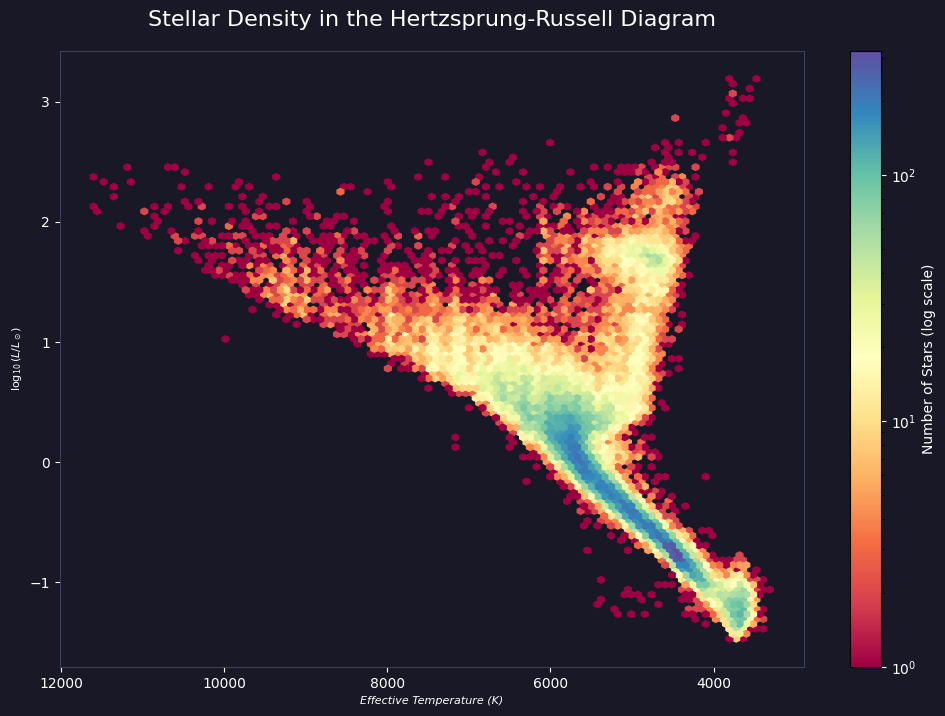

In [20]:
plt.figure(figsize=(12, 8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")
plt.hexbin(
    stars["teff_gspphot"],
    stars["log_luminosity"],
    gridsize=100,
    mincnt=1,
    bins="log",
    cmap="Spectral"
)

ax.invert_xaxis()
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("#39445c")
plt.xlabel("Effective Temperature (K)", color="white", fontsize=8, fontstyle='italic')
plt.ylabel(r"$\log_{10}(L/L_\odot)$", color="white", fontsize=8, fontstyle='italic')
plt.title("Stellar Density in the Hertzsprung-Russell Diagram", color="white",
         fontsize=16,
         pad=18)

cbar = plt.colorbar(label="Number of Stars (log scale)")
cbar.ax.yaxis.label.set_color("white")
cbar.ax.tick_params(colors="white")
plt.savefig("figures/Density_HR_diagram.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation of the Stellar Density

The density representation provides another view of the same stellar population by showing where stars are most concentrated within the HR diagram.

The highest density region follows the main-sequence, confirming that this is the dominant structure in the sample. A separate high-density region is also visible above the main-sequence, corresponding to a population of more luminous evolved stars.

The density plot also makes the lower luminosity population at cooler temperatures easier to distinguish. In contrast, the hotter region of the diagram contains considerably fewer stars.


## Identifying Stellar Populations

The next step is to investigate these regions using the physical properties available in the dataset.

In particular, we will compare temperature, luminosity, radius, mass, and age to understand how the stars in different regions of the HR diagram differ from one another.
The analysis will use the measured and derived stellar parameters to support the interpretation of these regions.

This will allow us to connect the visual structure of the HR diagram with the underlying physical properties of the stars.

Stellar mass is one of the most important physical properties influencing a star's evolution.
For main-sequence stars, mass is strongly related to temperature and luminosity (for example hotter stars have higher temperature and are more luminous).
<br>However, stars with similar temperatures can have very different luminosities once they evolve away from the main-sequence.

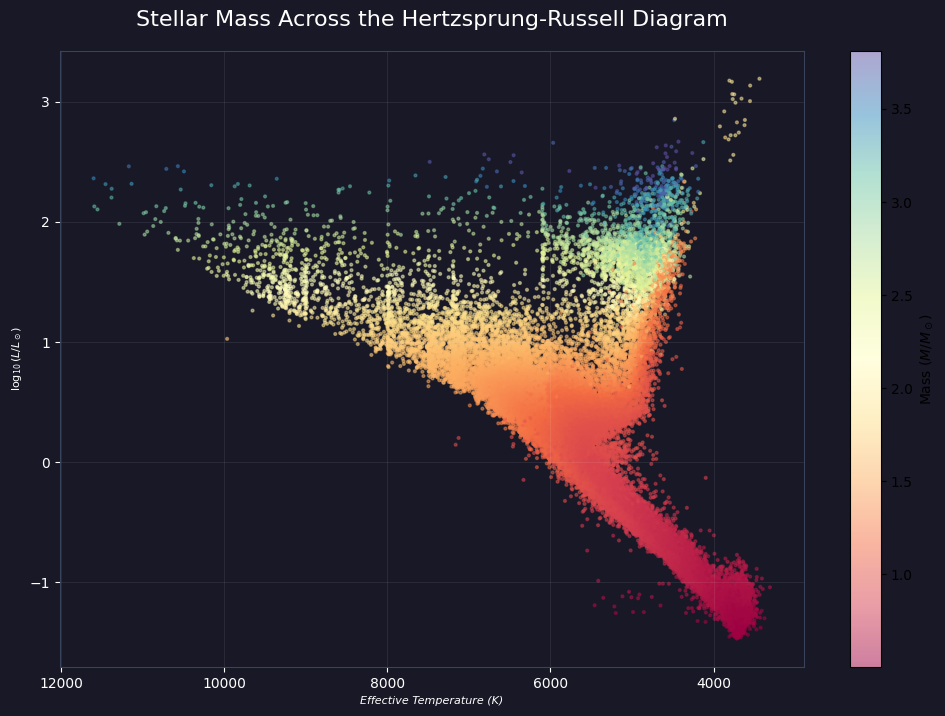

In [21]:
plt.figure(figsize=(12, 8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")
scatter = plt.scatter(
    stars['teff_gspphot'],
    stars['log_luminosity'],
    c=stars['mass_flame'],
    s=4,
    alpha=0.5,
    cmap="Spectral"
)

ax.invert_xaxis()
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(color="#FAFCFF", alpha=0.08)
plt.xlabel('Effective Temperature (K)',  color="white", fontsize=8, fontstyle='italic')
plt.ylabel(r'$\log_{10}(L/L_\odot)$',  color="white", fontsize=8, fontstyle='italic')
plt.title('Stellar Mass Across the Hertzsprung-Russell Diagram', color="white",
         fontsize=16,
         pad=18)
plt.colorbar(scatter, label=r"Mass ($M/M_\odot$)")
plt.savefig("figures/Mass_HR_diagram.png", dpi=300, bbox_inches="tight")
plt.show()

Along the main-sequence, stellar mass increases toward higher temperatures luminosities. But looking at the stars above the main-sequence, it shows that high-luminosity stars aren't necessarily high mass. The reason for that is an evolved star can become extremely luminous because its radius increases enormously, even though its mass may not be high. So let's investigate the parameter that explains this behaviour: Radius.
Stellar luminosity is related to temperature and radius through the Stefan-Boltzmann law:

$$ L = 4πR^2σT^4 $$

By this law, a plot visualizing the stellar radius across the HR diagram would look almost identical to the plot shown above, therefore it will not be displayed here to prevent redundancy.

### Mass-Luminosity Relationship
The HR diagram shows that stellar mass and luminosity are related, particularly along the main sequence.
In this section, the relationship between stellar mass and luminosity will be examined quantitatively. Because both quantities span a wide range, logarithmic transformations will be used to make the relationship easier to analyze.
The goal is to determine how strongly mass and luminosity are related in the observed stellar population and whether the relationship is consistent across the full sample.

Both stellar mass and luminosity are measured relative to the Sun. Since their distributions cover several orders of magnitude, logarithmic transformations provide a more suitable scale for examining their relationship.
The transformed variables will be used for both visualization and statistical analysis.

In [22]:
from scipy.stats import linregress

stars['log_mass'] = np.log10(stars['mass_flame'])

x = stars["log_mass"]
y = stars["log_luminosity"]

fit = linregress(x, y)

print(f"Pearson r = {fit.rvalue:.3f}")
print(f"R² = {fit.rvalue**2:.3f}")
print(f"Slope = {fit.slope:.3f}")
print(f"Intercept = {fit.intercept:.3f}")
print(f"p-value = {fit.pvalue:.3e}")

Pearson r = 0.968
R² = 0.938
Slope = 4.495
Intercept = 0.059
p-value = 0.000e+00


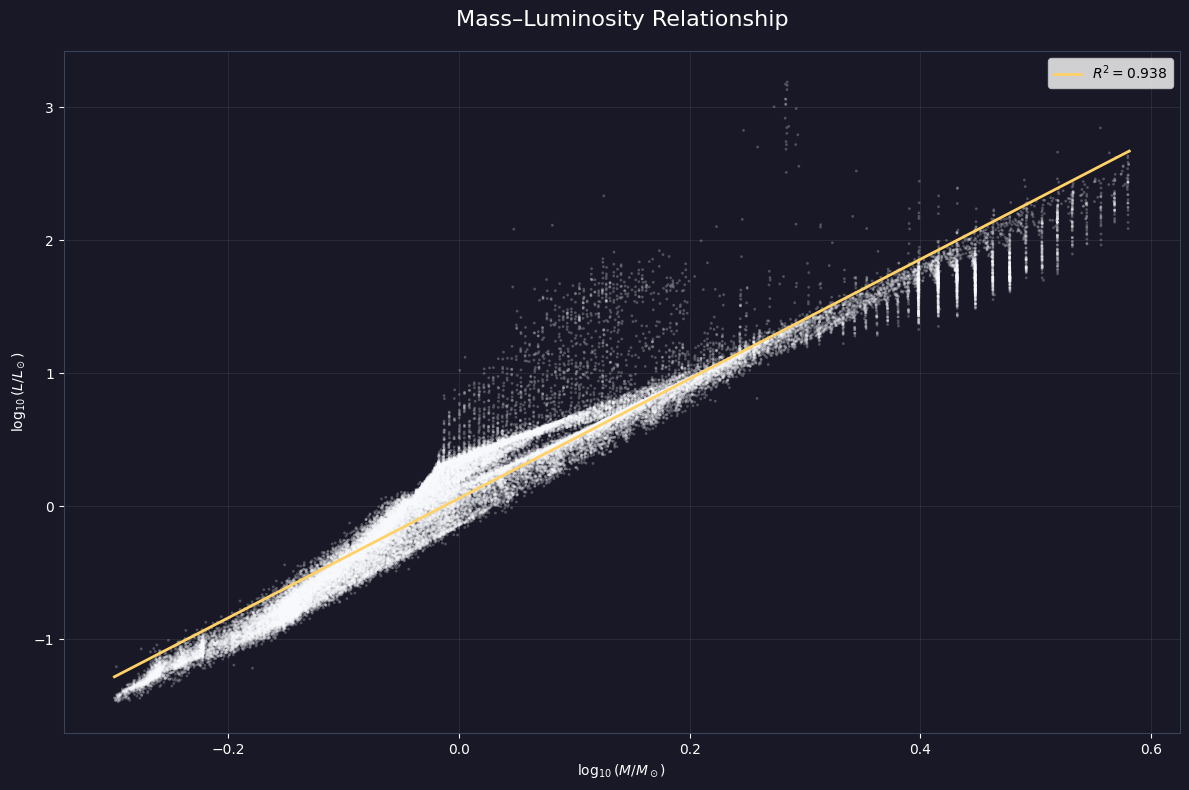

In [24]:
plt.figure(figsize=(12, 8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")

plt.scatter(
    stars["log_mass"],
    stars["log_luminosity"],
    s=4,
    alpha=0.25,
    color="#FAFCFF",
    edgecolors="none"
)

x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = fit.slope * x_fit + fit.intercept

plt.plot(
    x_fit,
    y_fit,
    color="#ffd166",
    linewidth=2,
    label=fr"$R^2 = {fit.rvalue**2:.3f}$"
)

plt.xlabel(r"$\log_{10}(M/M_\odot)$", color="white")
plt.ylabel(r"$\log_{10}(L/L_\odot)$", color="white")
plt.title(
    "Mass–Luminosity Relationship",
    color="white",
    fontsize=16,
    pad=18
)

ax.tick_params(colors="white")

for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(color="white", alpha=0.08)

plt.legend()
plt.tight_layout()
plt.savefig("figures/MassLum1diagram.png", dpi=300, bbox_inches="tight")
plt.show()

The Gaia-derived mass and luminosity estimates show a strong positive association across the selected sample, with a Pearson correlation coefficient of $0.968$ and an $R²$ of $0.938$. However, this relationship should be interpreted as a descriptive relationship within the Gaia-derived parameters rather than as an independent measurement of the universal stellar mass–luminosity law. The FLAME masses are model-derived from stellar luminosity and effective temperature using stellar evolution models.

## Stellar Populations
The Hertzsprung-Russell diagram shows that the stellar population is organized into distinct regions. The most prominent structure is the main-sequence. A second population of significantly more luminous stars appears above the main-sequence. These different regions correspond to stars with different physical properties and evolutionary histories.<br> In this section, the main stellar populations visible in the dataset will be examined and compared using their temperature, luminosity, mass and age.
### Example Stars Across the HR Diagram
The structures in the HR diagram represent stars with very different physical properties.
To make these differences more concrete, a small number of representative stars will be selected from different regions of the diagram. Their temperature, luminosity, mass, radius, and age will then be compared.
These stars are not intended to represent entire stellar populations. They just provide examples of how the physical properties of individual stars change across the HR diagram.

In [25]:
targets = {
    'cool, low luminosity' : (4000, -1.0),
    'main-squence' : (5500, 0.0),
    'hot, luminous' : (10000, 2.0),
    'cool, luminous' : (4000, 2)
}

representatives = []

for label, (target_temp, target_lum) in targets.items():
    distance= np.sqrt(
        ((stars['teff_gspphot'] - target_temp) / 1000) ** 2
        + (stars['log_luminosity'] - target_lum) ** 2
    )
    star = stars.loc[distance.idxmin()].copy()
    star['population'] = label
    representatives.append(star)
representatives = pd.DataFrame(representatives)

representatives[
    [
        "population",
        "source_id",
        "teff_gspphot",
        "lum_flame",
        "mass_flame",
        "radius_flame",
        "age_flame"
    ]
]

,population,source_id,teff_gspphot,lum_flame,mass_flame,radius_flame,age_flame
22423,"cool, low luminosity",6.712824e+18,3998.2422,0.099273,0.613798,0.658256,8.346839
15853,main-squence,5.796813e+18,5498.1280,1.002886,0.883218,1.098224,13.170992
14973,"hot, luminous",5.233053e+17,9943.9750,93.029280,2.787767,3.258992,0.352174
46696,"cool, luminous",6.734257e+18,4214.2040,126.698340,1.671880,21.075191,2.046856


### Comparing the Selected Stars

The selected stars illustrate how dramatically stellar properties can differ across the HR diagram.

In particular, stars with similar temperatures can have very different luminosities when their radii differ substantially. The comparison also shows that the hottest stars in the sample are not necessarily the oldest, while cooler and less luminous stars can have much longer inferred ages.

These examples provide a useful transition from the overall stellar population to the physical processes that drive stellar evolution.
<br>

A cleaner table would look like the following:

In [26]:
comparison = representatives[
    [
        "population",
        "teff_gspphot",
        "lum_flame",
        "mass_flame",
        "radius_flame",
        "age_flame"
    ]
].copy()

comparison.columns = [
    "Population",
    "Temperature (K)",
    "Luminosity (L/L☉)",
    "Mass (M/M☉)",
    "Radius (R/R☉)",
    "Age (Gyr)"
]

comparison.round(2)

,Population,Temperature (K),Luminosity (L/L☉),Mass (M/M☉),Radius (R/R☉),Age (Gyr)
22423,"cool, low luminosity",3998.24,0.10,0.61,0.66,8.35
15853,main-squence,5498.13,1.00,0.88,1.10,13.17
14973,"hot, luminous",9943.98,93.03,2.79,3.26,0.35
46696,"cool, luminous",4214.20,126.70,1.67,21.08,2.05


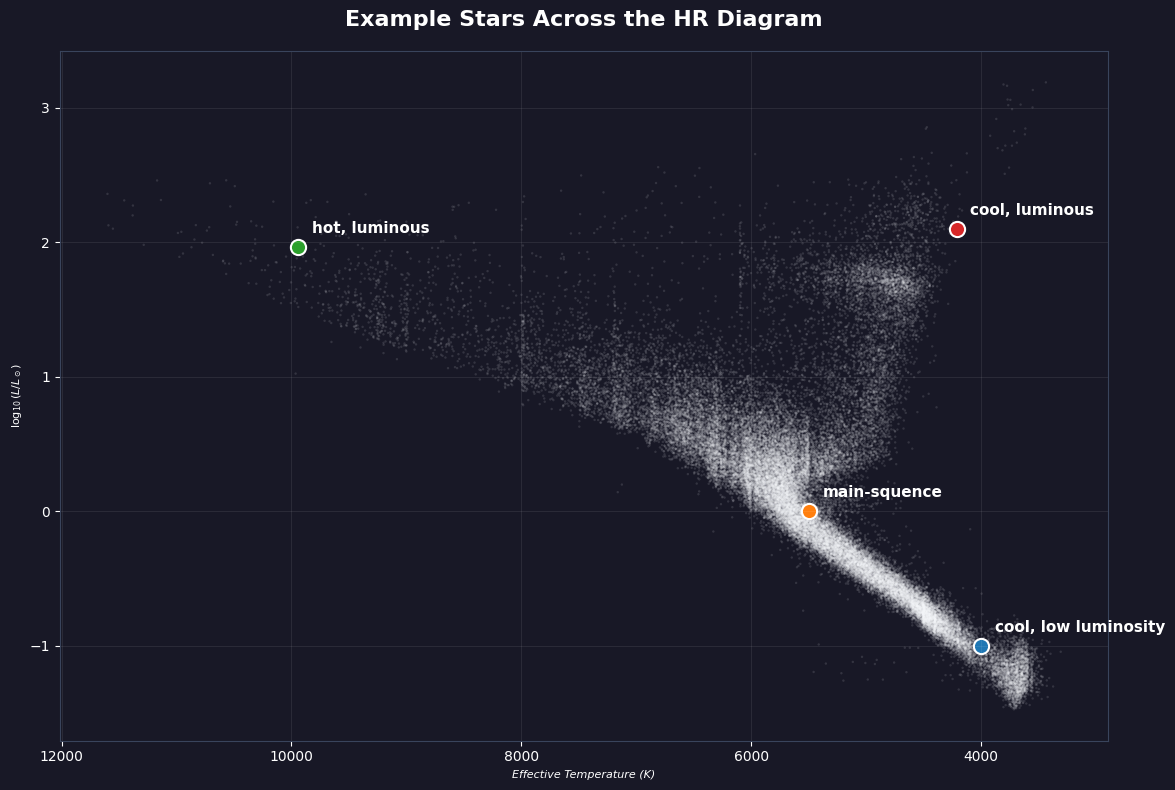

In [34]:
plt.figure(figsize=(12, 8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")

plt.scatter(
    stars["teff_gspphot"],
    stars["log_luminosity"],
    s=3,
    alpha=0.12,
    color="#FAFCFF",
    edgecolors="none"
)

for _, star in representatives.iterrows():
    plt.scatter(
        star["teff_gspphot"],
        star["log_luminosity"],
        s=120,
        edgecolors="white",
        linewidth=1.5
    )
    
    plt.annotate(
        star["population"],
        (star["teff_gspphot"], star["log_luminosity"]),
        xytext=(10, 10),
        textcoords="offset points",
        color="white",
        fontsize=11,
        fontweight="bold"
    )

ax.invert_xaxis()

plt.xlabel("Effective Temperature (K)", color="white", fontsize=8, fontstyle='italic')
plt.ylabel(r"$\log_{10}(L/L_\odot)$", color="white", fontsize=8, fontstyle='italic')

plt.title(
    "Example Stars Across the HR Diagram",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.tick_params(colors="white")

for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(color="white", alpha=0.08)

plt.tight_layout()
plt.savefig("figures/StarsAcrossHR.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation of the Representative Stars

The representative stars illustrate the wide range of physical properties present within the stellar population.

The cool, low-luminosity star lies along the lower part of the main-sequence, while the hot, luminous star occupies the hotter and more luminous region of the diagram. The cool, luminous star is particularly notable because its temperature is similar to the cool main-sequence star, yet its luminosity is dramatically higher. Its much larger radius provides an important explanation for this difference.

These examples show that stellar temperature, luminosity, mass, and radius are closely connected, but their relationships change as stars evolve. The HR diagram therefore provides a useful framework for linking observable stellar properties to different stages of stellar evolution.

# Sun Comparison

The Sun provides a useful reference point for interpreting the stellar population because its physical properties are well established.

In this section, the Sun will be placed on the Hertzsprung-Russell diagram alongside the Gaia stars. Its temperature and luminosity will then be compared with the stars in the dataset to identify where a solar-like star lies within the broader stellar population.

A Gaia star with properties closest to the Sun will also be identified and compared using temperature, luminosity, mass, radius, and age.

This comparison provides a familiar reference for interpreting the different stellar populations observed in the dataset.

In [35]:
# defining the sun's properties
sun_temperature = 5772
sun_luminosity = 1.0
sun_log_luminosity = np.log10(sun_luminosity)

sun_mass = 1.0
sun_radius = 1.0

print(f"Solar temperature: {sun_temperature} K")
print(f"Solar luminosity: {sun_luminosity} L☉")
print(f"Solar mass: {sun_mass} M☉")
print(f"Solar radius: {sun_radius} R☉")

Solar temperature: 5772 K
Solar luminosity: 1.0 L☉
Solar mass: 1.0 M☉
Solar radius: 1.0 R☉


### Locating the Sun on the Hertzsprung-Russell Diagram

The Sun can now be placed directly on the Hertzsprung-Russell diagram using its effective temperature and luminosity.

This provides a reference point for interpreting the Gaia stellar population and shows where a solar-type star lies relative to the different structures identified earlier.

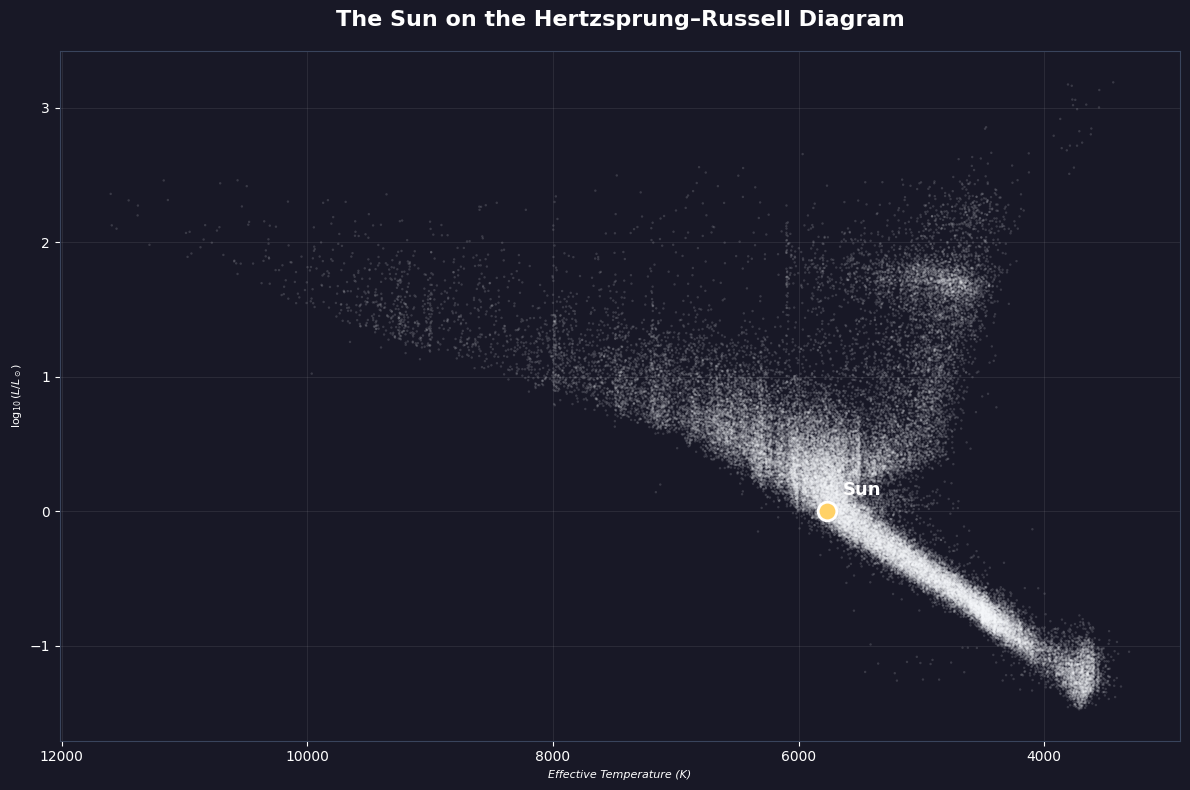

In [29]:
plt.figure(figsize=(12, 8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")

plt.scatter(
    stars["teff_gspphot"],
    stars["log_luminosity"],
    s=3,
    alpha=0.15,
    color="#FAFCFF",
    edgecolors="none"
)

plt.scatter(
    sun_temperature,
    sun_log_luminosity,
    s=180,
    color="#ffd166",
    edgecolors="white",
    linewidth=2,
    zorder=5,
    label="Sun"
)

plt.annotate(
    "Sun",
    (sun_temperature, sun_log_luminosity),
    xytext=(12, 12),
    textcoords="offset points",
    color="white",
    fontsize=13,
    fontweight="bold"
)

ax.invert_xaxis()

plt.xlabel("Effective Temperature (K)", color="white", fontsize=8, fontstyle="italic")
plt.ylabel(r"$\log_{10}(L/L_\odot)$", color="white", fontsize=8, fontstyle="italic")

plt.title(
    "The Sun on the Hertzsprung–Russell Diagram",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.tick_params(colors="white")

for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(color="white", alpha=0.08)

plt.tight_layout()
plt.savefig("figures/TheSun.png", dpi=300, bbox_inches="tight")
plt.show()

### Finding a Solar-like Star in the Gaia Sample

The Sun's position can also be compared with individual stars in the Gaia dataset.

A solar-like star will be identified by finding the observation with the smallest normalized distance from the Sun in temperature and luminosity. Both quantities are normalized so that neither dominates the comparison simply because of its numerical scale.

The selected star is not assumed to be an exact solar twin. It is only the star in this dataset whose position in the temperature–luminosity space is closest to that of the Sun.

In [30]:
stars["sun_distance"] = np.sqrt(
    ((stars["teff_gspphot"] - sun_temperature) / sun_temperature) ** 2
    +
    ((stars["log_luminosity"] - sun_log_luminosity) / 1) ** 2
)

solar_like = stars.loc[stars["sun_distance"].idxmin()]

solar_like[
    [
        "source_id",
        "teff_gspphot",
        "lum_flame",
        "mass_flame",
        "radius_flame",
        "age_flame",
        "sun_distance"
    ]
]

source_id       5.808230e+18
teff_gspphot    5.768674e+03
lum_flame       1.001181e+00
mass_flame      9.844633e-01
radius_flame    1.009530e+00
age_flame       5.643255e+00
sun_distance    7.712321e-04
Name: 46047, dtype: float64

### Comparing the Sun with a Gaia Solar-like Star

The Gaia sample contains a star whose temperature and luminosity are extremely close to those of the Sun.

The selected star has an effective temperature of approximately $5769 K$ and a luminosity of $1.001 L☉$, compared with the Sun's reference values of $5772 K$ and $1 L☉$. Its estimated mass and radius are also close to solar values.

This comparison demonstrates that the Gaia dataset contains stars occupying a region of the HR diagram very close to the Sun's position. However, the Gaia-derived age should be treated as a model-based estimate rather than an exact measurement.

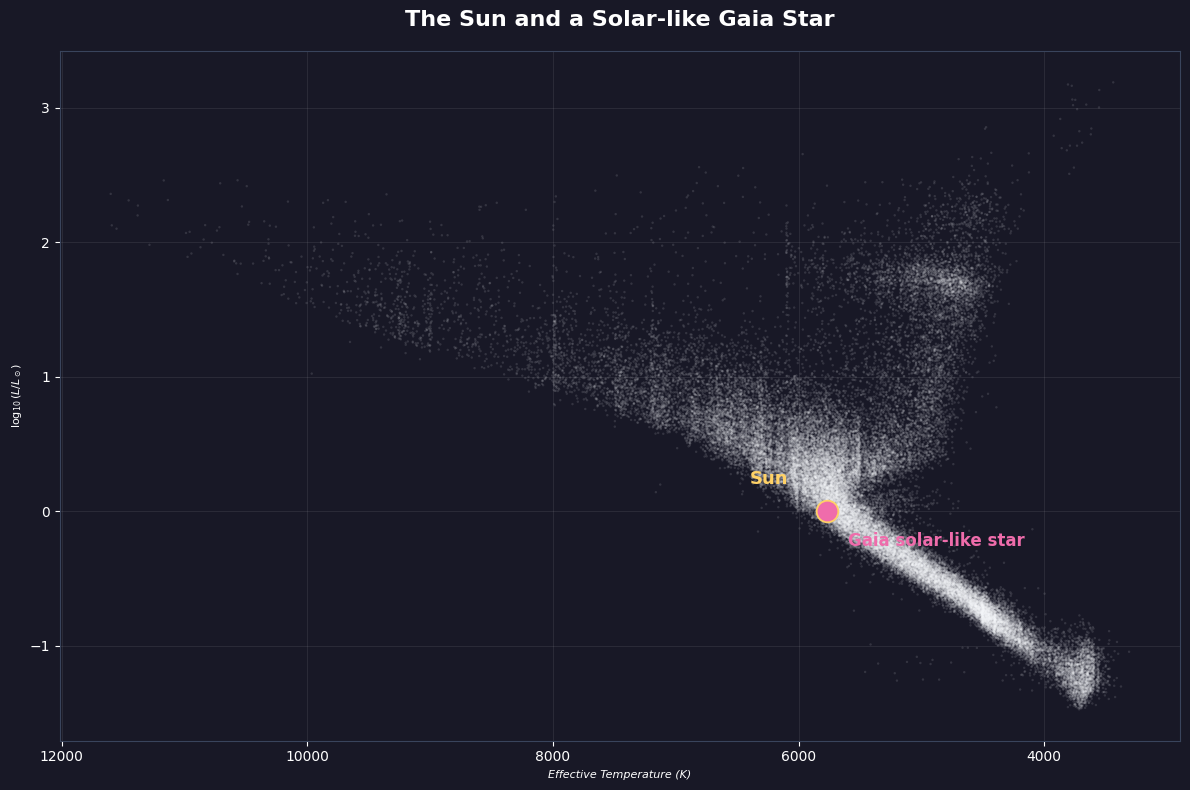

In [31]:
plt.figure(figsize=(12, 8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")

plt.scatter(
    stars["teff_gspphot"],
    stars["log_luminosity"],
    s=3,
    alpha=0.12,
    color="#FAFCFF",
    edgecolors="none"
)

plt.scatter(
    sun_temperature,
    sun_log_luminosity,
    s=220,
    color="#ffd166",
    edgecolors="#ffd166",
    linewidth=2,
    zorder=5
)

plt.annotate(
    "Sun",
    (sun_temperature, sun_log_luminosity),
    xytext=(-55, 20),
    textcoords="offset points",
    color="#ffd166",
    fontsize=13,
    fontweight="bold"
)

plt.scatter(
    solar_like["teff_gspphot"],
    solar_like["log_luminosity"],
    s=150,
    facecolors="#EF6CAB",
    edgecolors="#EF6CAB",
    linewidth=2,
    zorder=5
)

plt.annotate(
    "Gaia solar-like star",
    (solar_like["teff_gspphot"], solar_like["log_luminosity"]),
    xytext=(15, -25),
    textcoords="offset points",
    color="#EF6CAB",
    fontsize=12,
    fontweight="bold"
)

ax.invert_xaxis()

plt.xlabel("Effective Temperature (K)", color="white", fontsize=8, fontstyle="italic")
plt.ylabel(r"$\log_{10}(L/L_\odot)$", color="white", fontsize=8, fontstyle="italic")

plt.title(
    "The Sun and a Solar-like Gaia Star",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.tick_params(colors="white")

for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(color="white", alpha=0.08)

plt.tight_layout()
plt.savefig("figures/SolarlikeStar.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation

The Sun and the selected Gaia star occupy almost the same position on the Hertzsprung-Russell diagram. Their nearly identical temperatures and luminosities demonstrate how closely some stars in the Gaia sample resemble the Sun in their observable properties.

The Gaia star also has an estimated mass of approximately $0.98 M☉$ and a radius of approximately $1.01 R☉$, further supporting its classification as a solar-like star based on the available parameters.

This comparison provides a useful reference point for the next stage of the analysis, where the physical changes associated with stellar evolution will be examined.

# Stellar Evolution Analysis

The previous sections established that stars occupy distinct regions of the Hertzsprung-Russell diagram and that these regions are associated with different physical properties.

The next question is how these differences relate to stellar evolution.

Stars change their temperature, luminosity, radius, and internal structure throughout their lifetimes. The Gaia dataset also provides model-derived age estimates, which can be used to investigate how inferred stellar ages are distributed across the HR diagram.

In this section, the stellar population will be examined from an evolutionary perspective rather than simply comparing individual physical properties.

Because stellar ages in the Gaia dataset are model-derived, they will be interpreted as estimates and used primarily to identify population-level patterns.

### Age Distribution Across the HR Diagram

The HR diagram can be used to examine how inferred stellar age varies across different regions of the stellar population.

Each point will be colored according to its Gaia-derived age estimate. This allows regions containing relatively younger or older stars to be identified while preserving the underlying structure of the HR diagram.

The resulting pattern should be interpreted at the population level, since individual stellar ages depend on the models used to derive them.

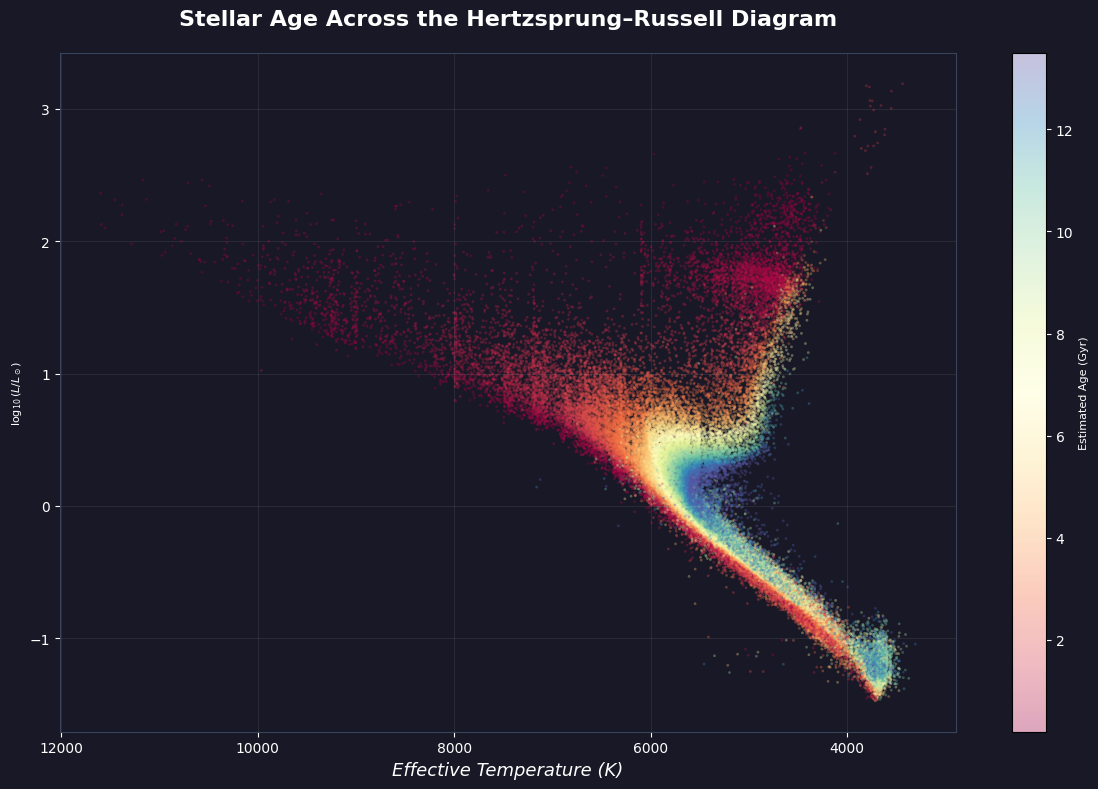

In [32]:
plt.figure(figsize=(12, 8), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")

scatter = plt.scatter(
    stars["teff_gspphot"],
    stars["log_luminosity"],
    c=stars["age_flame"],
    s=4,
    alpha=0.35,
    cmap="Spectral",
    edgecolors="none"
)

ax.invert_xaxis()

plt.xlabel(
    "Effective Temperature (K)",
    color="white",
    fontsize=13, 
    fontstyle="italic"
)

plt.ylabel(
    r"$\log_{10}(L/L_\odot)$",
    color="white",
    fontsize=8, 
    fontstyle="italic"
)

plt.title(
    "Stellar Age Across the Hertzsprung–Russell Diagram",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=20
)

cbar = plt.colorbar(scatter)
cbar.set_label(
    "Estimated Age (Gyr)",
    color="white",
    fontsize=8
)

cbar.ax.tick_params(colors="white")

ax.tick_params(colors="white")

for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(
    color="white",
    alpha=0.08,
    linewidth=0.8
)

plt.tight_layout()
plt.savefig("figures/StellarAge.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation

The age-colored HR diagram shows how Gaia's model-derived age estimates vary across the stellar population.

The main-sequence contains a broad range of inferred ages, while different regions of the diagram show different distributions of estimated age. The luminous population above the main sequence also exhibits a distinct age distribution.

These patterns are consistent with the different evolutionary states represented across the HR diagram. However, the age estimates are derived by Gaia FLAME from stellar luminosity and effective temperature using stellar evolution models. Therefore, this visualization should be interpreted as a model-based population-level comparison rather than as an independent measurement of stellar evolutionary history.

The age analysis is therefore most useful for showing how the Gaia-derived evolutionary estimates map onto the observed HR-diagram structure.

# Visual Storytelling

The analysis has shown that the 50,000 stars in the Gaia dataset are not randomly distributed in their physical properties.

The final stage brings the main findings together into a visual narrative. The goal is to move from the observed stellar population to the structure of the Hertzsprung-Russell diagram, then to representative stars, the Sun, and finally the evolutionary differences revealed by the dataset.

This section focuses on presenting the strongest results in a clear and visually consistent way.

### Mapping the Stellar Sample

The Gaia catalogue provides the sky coordinates of each observed source. These coordinates can be transformed into Galactic coordinates to visualize how the stellar sample is distributed across the sky.

This provides a visual introduction to the dataset before examining the physical properties of the stars.

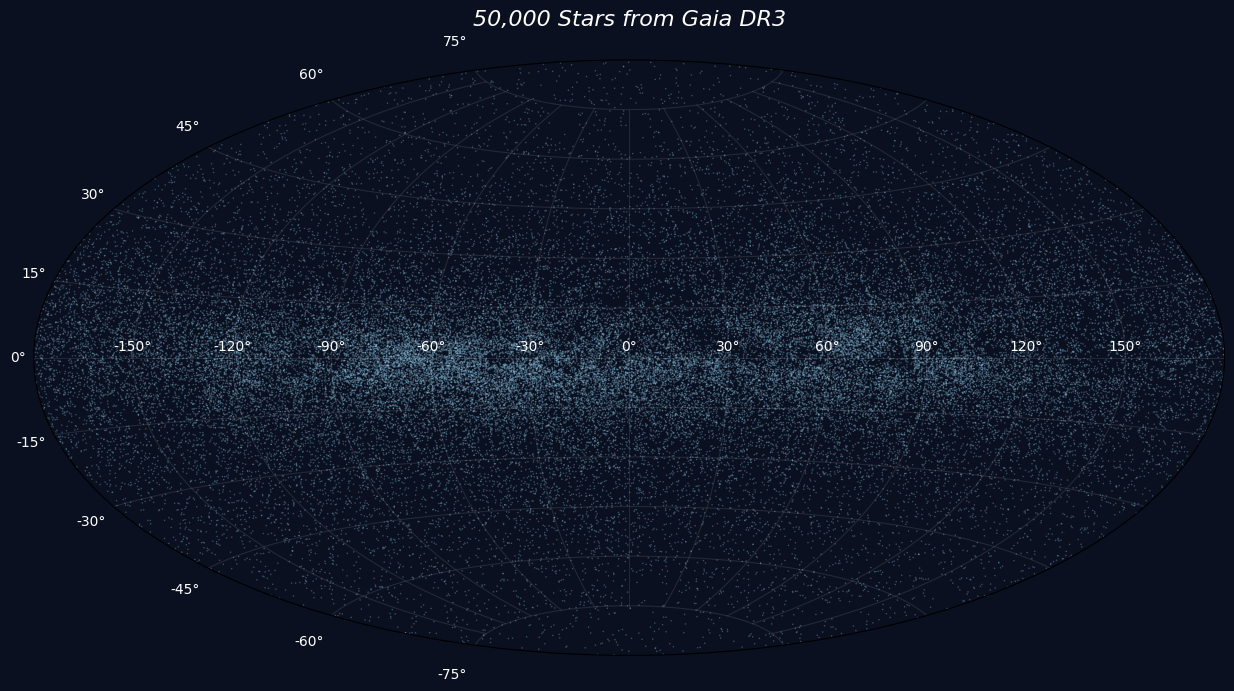

In [56]:
from astropy.coordinates import SkyCoord
import astropy.units as u

coords = SkyCoord(
    ra=stars["ra"].values * u.deg,
    dec=stars["dec"].values * u.deg,
    frame="icrs"
)

galactic = coords.galactic

l = galactic.l.wrap_at(180 * u.deg).radian
b = galactic.b.radian

plt.figure(figsize=(14, 7), facecolor="#0b1020")
ax = plt.subplot(111, projection="aitoff")
ax.set_facecolor("#0b1020")

ax.scatter(
    l,
    b,
    s=1.2,
    alpha=0.35,
    color="#8ecae6",
    edgecolors="none"
)

ax.grid(color="white", alpha=0.10)

plt.title(
    "50,000 Stars from Gaia DR3",
    color="white",
    fontsize=16,
    fontstyle="italic",
    pad=25
)

ax.tick_params(colors="white")

plt.tight_layout()
plt.savefig("figures/GaiaStars.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation of the Gaia Stellar Map

The sky distribution of the 50,000 Gaia sources shows a clear concentration along the Galactic plane. This structure reflects the distribution of stars within the Milky Way, where a large fraction of the stellar population is concentrated around the Galactic disk.

This map provides the spatial context for the analysis that follows. Although the stars are distributed across the sky, their physical properties reveal an additional layer of structure that becomes visible in the HR diagram.

### The Hidden Structure of the Stellar Population

The sky map provides the spatial context for the dataset, but the physical structure of the stars becomes visible when their temperature and luminosity are examined.

The HR diagram reveals that the 50,000 stars are not randomly distributed. They actually form distinct structures, with the main-sequence containing the majority of the population and more luminous stars appearing above it.

This diagram forms the central visual of the project because it connects the measured stellar properties to the different populations and evolutionary states explored throughout the analysis.

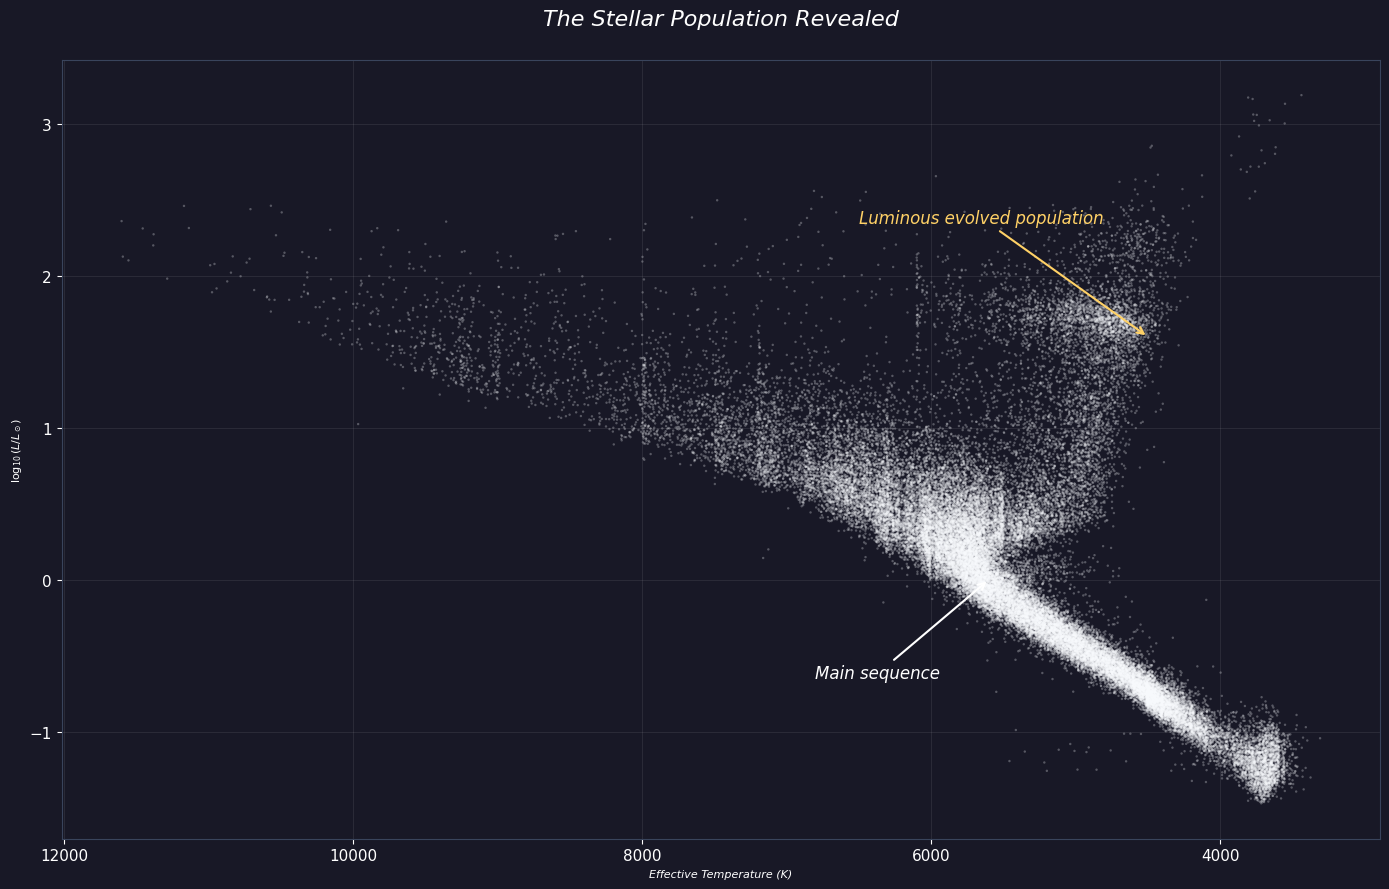

In [59]:
plt.figure(figsize=(14, 9), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")


plt.scatter(
    stars["teff_gspphot"],
    stars["log_luminosity"],
    s=3,
    alpha=0.28,
    color="#FAFCFF",
    edgecolors="none"
)

plt.annotate(
    "Main sequence",
    xy=(5600, 0.0),
    xytext=(6800, -0.65),
    color="white",
    fontsize=12,
    fontstyle="italic",
    arrowprops=dict(
        arrowstyle="->",
        color="white",
        lw=1.5
    )
)

plt.annotate(
    "Luminous evolved population",
    xy=(4500, 1.6),
    xytext=(6500, 2.35),
    color="#ffd166",
    fontsize=12,
    fontstyle="italic",
    arrowprops=dict(
        arrowstyle="->",
        color="#ffd166",
        lw=1.5
    )
)

ax.invert_xaxis()

plt.xlabel(
    "Effective Temperature (K)",
    color="white",
    fontsize=8,
    fontstyle="italic"
)

plt.ylabel(
    r"$\log_{10}(L/L_\odot)$",
    color="white",
    fontsize=8,
    fontstyle="italic"
)

plt.title(
    "The Stellar Population Revealed",
    color="white",
    fontsize=16,
    fontstyle="italic",
    pad=25
)

ax.tick_params(
    colors="white",
    labelsize=11
)

for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(
    color="white",
    alpha=0.08,
    linewidth=0.8
)

plt.tight_layout()
plt.savefig("figures/FinalHRFig.png", dpi=300, bbox_inches="tight")
plt.show()

### Representative Stars Across the HR Diagram

The Hertzsprung-Russell diagram contains a wide range of stellar properties, but individual examples make these differences easier to understand.

Four representative stars are highlighted across different regions of the diagram. Their positions illustrate how temperature and luminosity can vary across the stellar population, while their physical parameters provide additional context for interpreting these regions.

These stars are used as examples rather than formal classifications of the entire population.

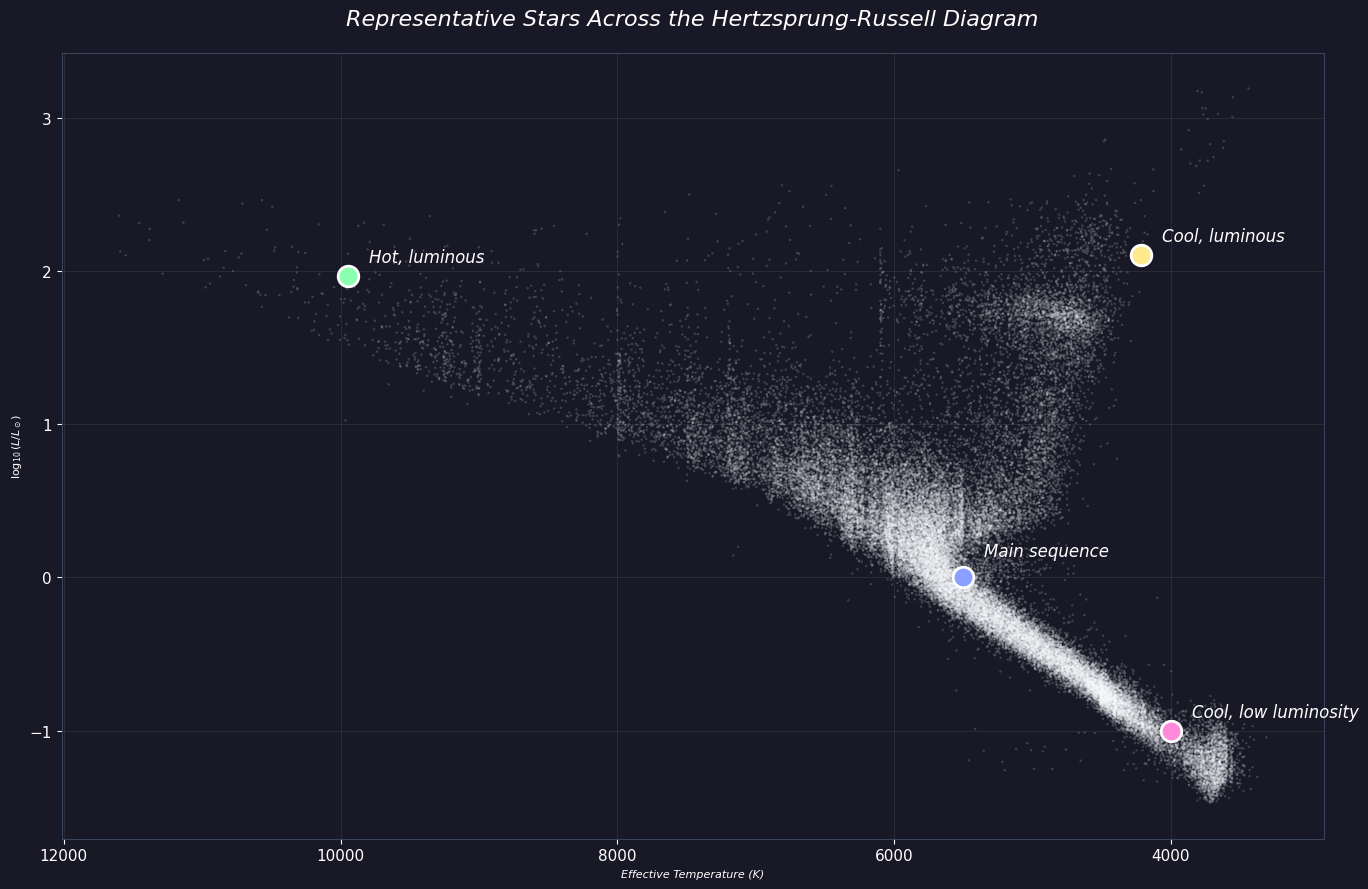

In [36]:
plt.figure(figsize=(14, 9), facecolor="#181826")
ax = plt.gca()
ax.set_facecolor("#181826")

plt.scatter(
    stars["teff_gspphot"],
    stars["log_luminosity"],
    s=3,
    alpha=0.18,
    color="#FAFCFF",
    edgecolors="none"
)

colors = ["#FF8ADA", "#8A9FFF", "#8AFFAF", "#FFE98A"]

for (_, star), color in zip(representatives.iterrows(), colors):

    plt.scatter(
        star["teff_gspphot"],
        star["log_luminosity"],
        s=220,
        color=color,
        edgecolors="white",
        linewidth=2,
        zorder=5
    )

labels = [
    "Cool, low luminosity",
    "Main sequence",
    "Hot, luminous",
    "Cool, luminous"
]

offsets = [
    (15, 10),
    (15, 15),
    (15, 10),
    (15, 10)
]

for (_, star), label, offset in zip(
    representatives.iterrows(),
    labels,
    offsets
):

    plt.annotate(
        label,
        (
            star["teff_gspphot"],
            star["log_luminosity"]
        ),
        xytext=offset,
        textcoords="offset points",
        color="white",
        fontsize=12,
        fontstyle="italic"
    )

ax.invert_xaxis()

plt.xlabel(
    "Effective Temperature (K)",
    color="white",
    fontsize=8,
    fontstyle="italic"
)

plt.ylabel(
    r"$\log_{10}(L/L_\odot)$",
    color="white",
    fontsize=8,
    fontstyle="italic"
)

plt.title(
    "Representative Stars Across the Hertzsprung-Russell Diagram",
    color="white",
    fontsize=16,
    fontstyle="italic",
    pad=20
)

ax.tick_params(colors="white", labelsize=11)

for spine in ax.spines.values():
    spine.set_color("#39445c")

ax.grid(
    color="white",
    alpha=0.08,
    linewidth=0.8
)

plt.tight_layout()
plt.savefig("figures/RepresentativeStars.png", dpi=300, bbox_inches="tight")
plt.show()

# Conclusion

This project used a selected sample of 50,000 stars from the Gaia Data
Release 3 catalogue to investigate the physical structure of a stellar sample
and explore how stellar properties relate to stellar evolution.

The analysis began by deriving stellar distances and extinction-uncorrected
absolute G magnitudes from Gaia observations. The resulting color-magnitude
and Hertzsprung-Russell diagrams revealed clear structure within the sample,
including a dominant main sequence and a more luminous population of evolved
stars.

Additional analysis showed that stellar temperature, luminosity, mass, and
radius are strongly interconnected. The Gaia derived mass and luminosity
estimates also exhibited a strong positive association across the selected
sample. However, this relationship is interpreted as a descriptive result
because Gaia FLAME derives stellar masses using luminosity, effective
temperature, and stellar evolution models.

The representative-star analysis demonstrated how stars with similar
temperatures can have substantially different luminosities, particularly when
their radii differ. This provided a useful physical explanation for the
position of evolved stars above the main sequence.

The Sun was then placed within the Gaia sample, and a star with an HR diagram
position extremely close to the Sun was identified. Its effective temperature
of approximately 5,769 K and luminosity of 1.001 L☉ are very close to the
adopted solar reference values.

Finally, Gaia derived age estimates were mapped across the HR diagram. These
estimates showed different age distributions across regions of the stellar
sample, providing an additional model-based perspective on stellar evolution.

Overall, the project demonstrates how large astronomical survey datasets can
be transformed into scientific insight through data preparation, quantitative
analysis, statistical methods, scientific visualization, and careful
interpretation of model-derived parameters.

## Data & References

### Primary Data Source

- Gaia Collaboration. (2023). *Gaia Data Release 3: Summary of the content and survey properties*. Astronomy & Astrophysics, 674, A1.
  https://doi.org/10.1051/0004-6361/202243940

### Gaia Documentation

- European Space Agency / Gaia DPAC. *Gaia Data Release 3 Documentation*.
  https://gea.esac.esa.int/archive/documentation/GDR3/

- Gaia DR3 `gaia_source` Data Model.
  https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_main_source_catalogue/ssec_dm_gaia_source.html

- Gaia DR3 Astrophysical Parameters / FLAME.
  https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_astrophysical_parameter_tables/ssec_dm_astrophysical_parameters.html